# Chapitre 4 - Cours 2 : Thrift et Protocol Buffers, numéros de champ et évolution de schéma

Le cours 1 a montré qu'un format sans schéma doit répéter les noms de champs dans chaque
enregistrement. Apache Thrift (né chez Facebook) et Protocol Buffers (protobuf, conçu chez
Google) imposent un **schéma** et remplacent les noms par de petits **numéros de champ**
(field tags). Ce cours construit leurs encodeurs à la main, octet par octet, puis étudie
comment ces numéros organisent l'évolution du schéma. Il couvre la section *Thrift and
Protocol Buffers* et ses sous-sections *Field tags and schema evolution* et *Datatypes
and schema evolution*.

**Plan.**

1. Un schéma, une IDL et du code généré.
2. Les entiers de longueur variable : varint et zigzag.
3. L'enregistrement d'exemple en Thrift et en Protocol Buffers, octet par octet.
4. Numéros de champ et évolution du schéma : ajouter, supprimer, préserver l'inconnu.
5. Changer le type d'un champ.
6. Une matrice de compatibilité testée automatiquement.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import encoding as E
from ddia.encoding import PbField, PbMessage
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
R = E.EXAMPLE_RECORD
RP = E.to_pb_record(R)          # mêmes données, noms de champs à la mode protobuf

## 1. Un schéma, une IDL et du code généré (section *Thrift and Protocol Buffers*)

Protocol Buffers exige un schéma pour toute donnée encodée. On l'écrit dans un **langage
de définition d'interface** (IDL). Pour l'enregistrement d'exemple :

```thrift
struct Person {
  1: required string       userName,
  2: optional i64          favoriteNumber,
  3: optional list<string> interests
}
```

```protobuf
message Person {
    required string user_name       = 1;
    optional int64  favorite_number = 2;
    repeated string interests       = 3;
}
```

Chaque champ a un **type**, un **nom** et surtout un **numéro** ; les deux IDL marquent
aussi chaque champ comme obligatoire (`required`) ou facultatif (`optional`). Thrift a un
vrai type liste (`list<string>`) ; protobuf indique une liste par le mot-clé `repeated`.
Notre module représente le schéma protobuf par un objet Python (`E.PERSON_PB`, écrit en
syntaxe proto3 où tout champ est facultatif) :

In [2]:
print(E.PERSON_PB.to_proto())

message Person {
    string user_name = 1;
    int64 favorite_number = 2;
    repeated string interests = 3;
}


Un **générateur de code** lit le schéma et produit, pour chaque langage, des classes qui
savent encoder et décoder les enregistrements conformes. L'application manipule ces
classes ; le format binaire lui reste caché. Le langage de schéma est volontairement
pauvre : des champs et des types, sans contraintes de validation sur les valeurs (pas de
« entre 1 et 65 535 » comme en JSON Schema).

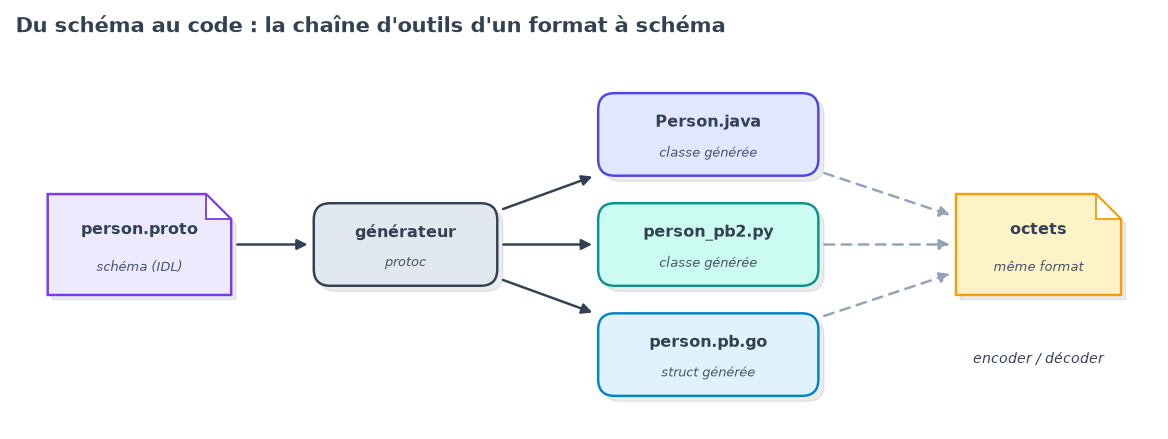

In [3]:
d = Diagram(12.5, 4.0, title="Du schéma au code : la chaîne d'outils d'un format à schéma")
d.box("idl", 1.4, 2.0, "person.proto", sub="schéma (IDL)", color=VIOLET, kind="doc", w=2.0, h=1.1)
d.box("gen", 4.3, 2.0, "générateur", sub="protoc", color=SLATE, w=2.0)
d.box("java", 7.6, 3.2, "Person.java", sub="classe générée", color=INDIGO, w=2.4)
d.box("py", 7.6, 2.0, "person_pb2.py", sub="classe générée", color=TEAL, w=2.4)
d.box("go", 7.6, 0.8, "person.pb.go", sub="struct générée", color=SKY, w=2.4)
d.box("bytes", 11.2, 2.0, "octets", sub="même format", color=AMBER, kind="doc", w=1.8, h=1.1)
d.arrow("idl", "gen")
for k in ("java", "py", "go"):
    d.arrow("gen", k)
    d.arrow(k, "bytes", style="dashed", color=GRAY)
d.note(11.2, 0.75, "encoder / décoder", color=SLATE)
d.show()

> **À retenir.** Thrift et Protocol Buffers décrivent les données par un schéma écrit dans une
> IDL, où chaque champ porte un numéro ; un générateur produit le code d'encodage et de
> décodage pour chaque langage.